In [159]:
import pandas as pd
df = pd.read_csv("shirt_sizes_long.csv")
print(df.head())

   height(cm)  weight(kg) t-shirt size
0         158          58            M
1         158          59            M
2         158          63            M
3         160          59            M
4         160          60            M


## Machine Learning Models Sci-kit learn

When creating a model in Sci-kit learn, it needs two things:

1. $X$: feature matrix (2D data structure)
    - rows are instances and columns are attributes/features
1. $y$: class column (1D data structure)
    - the attribute/feature we want to predict
    - AKA: target array, target vector, labels, etc

*_train* and *_test* are used denote the training and testing sets, respectively

In [160]:
X = df.drop(["t-shirt size"], axis="columns")
y = df["t-shirt size"]
print(X.head())
print(y.head())

   height(cm)  weight(kg)
0         158          58
1         158          59
2         158          63
3         160          59
4         160          60
0    M
1    M
2    M
3    M
4    M
Name: t-shirt size, dtype: str


## Train/Test Method One: Holdout Method
- hold out some instances for testing
- common ratios: 70-30, 75-25, 90-10

In [161]:
from sklearn.model_selection import train_test_split
# python -m pip install scikit-learn

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)
print("X_train", X_train.head(), X_train.shape)
print("y_train", y_train.head(), y_train.shape)
print(X_test.shape, y_test.shape)
print(y_train.value_counts())

X_train     height(cm)  weight(kg)
7          160          64
11         165          65
9          165          61
2          158          63
10         165          62 (14, 2)
y_train 7     L
11    L
9     L
2     M
10    L
Name: t-shirt size, dtype: str (14,)
(4, 2) (4,)
t-shirt size
L    9
M    5
Name: count, dtype: int64


In [162]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
scaler.fit(X_train)
X_train_norm = scaler.transform(X_train)
X_test_norm = scaler.transform(X_test)
print(X_train_norm)
print(X_test_norm)

[[0.16666667 0.6       ]
 [0.58333333 0.7       ]
 [0.58333333 0.3       ]
 [0.         0.5       ]
 [0.58333333 0.4       ]
 [1.         1.        ]
 [0.41666667 0.6       ]
 [0.         0.        ]
 [0.         0.1       ]
 [1.         0.6       ]
 [0.83333333 0.8       ]
 [0.41666667 0.2       ]
 [0.83333333 0.5       ]
 [0.16666667 0.2       ]]
[[0.16666667 0.1       ]
 [1.         0.5       ]
 [0.41666667 0.3       ]
 [0.83333333 0.4       ]]


In [163]:
from sklearn.neighbors import KNeighborsClassifier

knn_clf = KNeighborsClassifier(n_neighbors=3, metric="euclidean")
knn_clf.fit(X_train_norm, y_train)
y_predicted = knn_clf.predict(X_test_norm)
print(list(y_predicted))
print(list(y_test))

['M', 'L', 'L', 'L']
['M', 'L', 'M', 'L']


KNN 3 Accuracy: 0.75
[[2 0]
 [1 1]]


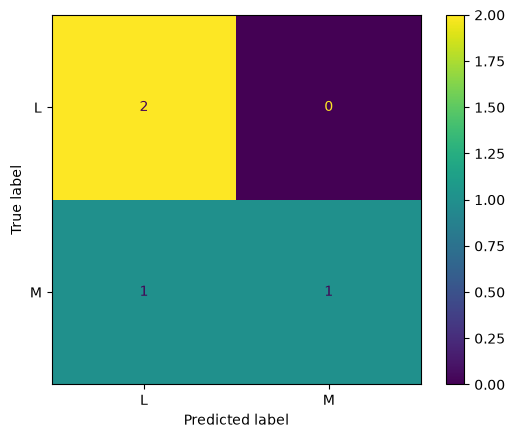

In [164]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

acc_knn = accuracy_score(y_test, y_predicted)
print(f"KNN 3 Accuracy: {acc_knn}")

cm_knn = confusion_matrix(y_test, y_predicted)
print(cm_knn)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=knn_clf.classes_)
disp.plot()

['M', 'L', 'L', 'L']
['M', 'L', 'M', 'L']


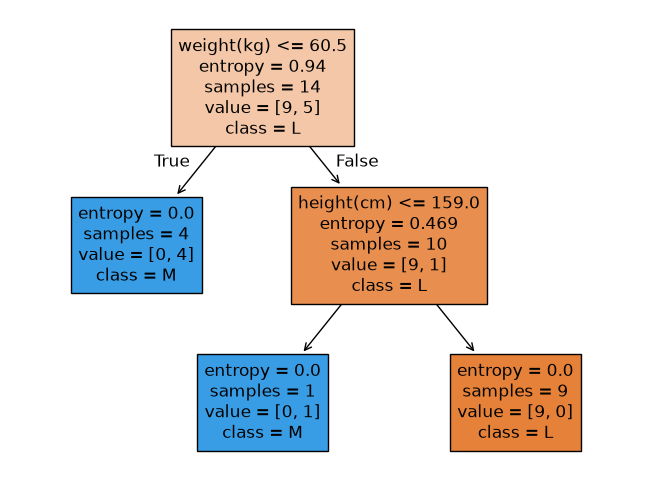

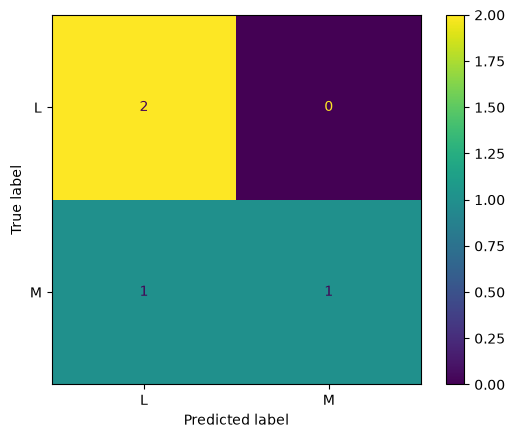

In [166]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

tree_clf = DecisionTreeClassifier(criterion="entropy")
tree_clf.fit(X_train, y_train)
y_pred_tree = tree_clf.predict(X_test)
print(list(y_pred_tree))
print(list(y_test))

plt.figure(layout="constrained")
plot_tree(tree_clf, feature_names=X.columns, class_names=tree_clf.classes_, filled=True)
plt.show()

tree_acc = accuracy_score(y_test, y_pred_tree)
cm_tree = confusion_matrix(y_test, y_pred_tree)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_tree, display_labels=tree_clf.classes_)
disp.plot()

## Closing Thoughts on kNN

- Inefficient alg
- What if you have features that are categorical?
  - Encode values as integers (0, 1, 2,...)
    - Sci-kit learn's LabelEncoder
    - Ok if category is ordinal (can be ordered)
    - Numbering adds an inherent ordering that will effect distances
  - Use another distance function, or create our own!
- kNN is one of MANY supervised ML algorithms
  - Decision Trees
  - Random forests
  - Naive Bayes
  - Support Vector Machines
  - Neural Networks!
  - etc. 